In [1]:
# dividing the dataset into 3 clusters (types of customers)
import os
import pandas as pd
import kagglehub
import pickle
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

/Users/anujsarita/Documents/flight-sagemaker-project/demo/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("itsmesunil/bank-loan-modelling")
file_path = os.path.join(path, "Bank_Personal_Loan_Modelling.xlsx")
# Load the Excel file and convert it to pandas DataFrame
df = pd.read_excel(file_path, sheet_name=1, engine='openpyxl')
df.columns

Index(['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='str')

In [3]:
df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [5]:
zeros = (df==0).sum()
print(zeros)

ID                       0
Age                      0
Experience              66
Income                   0
ZIP Code                 0
Family                   0
CCAvg                  106
Education                0
Mortgage              3462
Personal Loan         4520
Securities Account    4478
CD Account            4698
Online                2016
CreditCard            3530
dtype: int64


In [6]:
df.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937913,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747666,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
filtered_cols = [col for col in numeric_cols if df[col].nunique() > 15]
print("Columns considered for Z-score outlier detection:")
print(filtered_cols)
z_scores = stats.zscore(df[filtered_cols]) 
# convert to dataframe
z_df = pd.DataFrame(z_scores, columns=filtered_cols)
threshold = 3
# prevent data loss by creating a copy of the original dataframe
df_clean = df.copy()
outliers_dict = {}                            
for col in filtered_cols:
    if col not in ["ID", "ZIP Code"]:
        mask = np.abs(z_df[col]) > threshold
        outliers = df.loc[mask, col]
        if not outliers.empty:
            outliers_dict[col] = outliers
            print(f"\nOutliers detected in column '{col}':")
            print(outliers)
            # Replace outliers with mean
            mean_val = int(df[col].mean())
            df_clean.loc[mask, col] = mean_val
            print(f"Replaced outliers in '{col}' with mean: {mean_val}")
print("\nSummary of Outlier Counts After Replacement:")
for col, vals in outliers_dict.items():
    print(f"{col}: {len(vals)} outliers replaced")


Columns considered for Z-score outlier detection:
['ID', 'Age', 'Experience', 'Income', 'ZIP Code', 'CCAvg', 'Mortgage']

Outliers detected in column 'Income':
3896    224
4993    218
Name: Income, dtype: int64
Replaced outliers in 'Income' with mean: 73

Outliers detected in column 'CCAvg':
9       8.9
18      8.1
55      8.0
131     7.2
145     7.4
       ... 
4652    8.0
4679    7.2
4782    7.2
4911    7.5
4937    8.6
Name: CCAvg, Length: 121, dtype: float64
Replaced outliers in 'CCAvg' with mean: 1

Outliers detected in column 'Mortgage':
42      412
59      455
119     366
288     391
303     617
       ... 
4672    550
4698    400
4812    612
4842    590
4859    541
Name: Mortgage, Length: 105, dtype: int64
Replaced outliers in 'Mortgage' with mean: 56

Summary of Outlier Counts After Replacement:
Income: 2 outliers replaced
CCAvg: 121 outliers replaced
Mortgage: 105 outliers replaced


In [8]:
# data cleaning for experience column
print(df[df['Experience']<0]['Experience'].count())
print(df[df['Experience']<0]['Experience'].value_counts())
df['Experience'] = df['Experience'].apply(abs)

52
Experience
-1    33
-2    15
-3     4
Name: count, dtype: int64


In [9]:
corr_matrix = df.corr()
print(corr_matrix)

                          ID       Age  Experience    Income  ZIP Code  \
ID                  1.000000 -0.008473   -0.008202 -0.017695  0.013432   
Age                -0.008473  1.000000    0.993991 -0.055269 -0.029216   
Experience         -0.008202  0.993991    1.000000 -0.046876 -0.028936   
Income             -0.017695 -0.055269   -0.046876  1.000000 -0.016410   
ZIP Code            0.013432 -0.029216   -0.028936 -0.016410  1.000000   
Family             -0.016797 -0.046418   -0.051851 -0.157501  0.011778   
CCAvg              -0.024672 -0.052030   -0.049750  0.645993 -0.004068   
Education           0.021463  0.041334    0.013919 -0.187524 -0.017377   
Mortgage           -0.013920 -0.012539   -0.011097  0.206806  0.007383   
Personal Loan      -0.024801 -0.007726   -0.008304  0.502462  0.000107   
Securities Account -0.016972 -0.000436   -0.000989 -0.002616  0.004704   
CD Account         -0.006909  0.008043    0.009735  0.169738  0.019972   
Online             -0.002528  0.013702

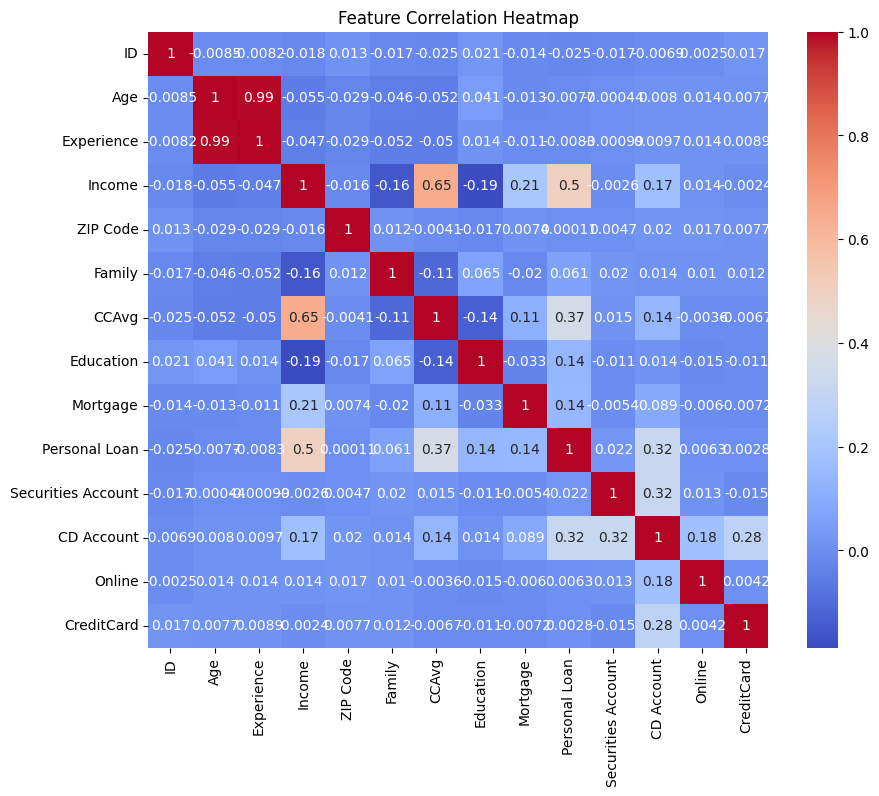

In [10]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
threshold = 0.9
high_corr = np.where(np.abs(corr_matrix) > threshold)
# feature pairs with high correlation
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr) if x != y and x < y]
print("Highly correlated pairs (>0.9):", high_corr_pairs)

Highly correlated pairs (>0.9): [('Age', 'Experience')]


In [12]:
# feature scaling mean = 0 and standard deviation = 1
# ensures all features contribute equally.
scaler = StandardScaler()  
X_scaled = scaler.fit_transform(df[['Age','Experience', 'Income', 'Family', 'CCAvg']])
print(X_scaled)

[[-1.77441684 -1.67640794 -0.53822878  1.39741398 -0.19337053]
 [-0.02952359 -0.09940383 -0.8641094   0.52599094 -0.25059542]
 [-0.55299157 -0.44984918 -1.36379301 -1.21685513 -0.53671986]
 ...
 [ 1.54088033  1.65282296 -1.08136314 -0.34543209 -0.93729408]
 [ 1.71536965  1.7404343  -0.53822878  0.52599094 -0.82284431]
 [-1.51268285 -1.41357392  0.20043396  0.52599094 -0.65116964]]


In [13]:
# To reduce redundancy, improve computational efficiency
# Keep enough principal components to retain 90% of the variance
# pca combines correlated features into principal components, so we can reduce dimensionality while retaining most of the information
pca = PCA(n_components=0.90)
X_reduced = pca.fit_transform(X_scaled)
print(X_reduced.shape) 

(5000, 3)


Optimal number of clusters according to Silhouette Coefficient: 3
[0.30732668198068047, 0.3429246745043718, 0.3194868867653068, 0.3139696656011071, 0.3145840696643139, 0.298328124652259, 0.28620758145736175, 0.2894638197762008, 0.2800970046767929]


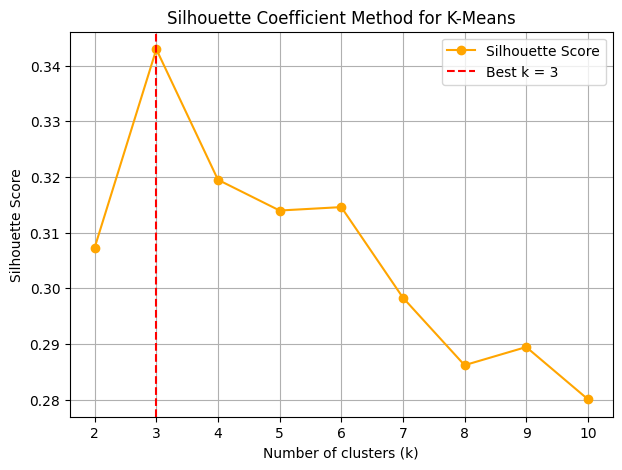

In [ ]:
# finding optimal clusters using silhouette coefficient
s_score = []
k_values = range(2, 11)
for k in range(2, 11):  # k = 2 to 10
    kmeans = KMeans(n_clusters=k, random_state=42)
    # find cluster center
    labels = kmeans.fit_predict(X_reduced)
    # measure cluster quality 
    score = silhouette_score(X_reduced, labels)
    s_score.append(score)
best_k = k_values[np.argmax(s_score)]
print(f"Optimal number of clusters according to Silhouette Coefficient: {best_k}")
print(s_score)
plt.figure(figsize=(7,5))
plt.plot(k_values, s_score, marker='o', color='orange', label='Silhouette Score')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Coefficient Method for K-Means')
plt.legend()
plt.grid(True)
plt.show()

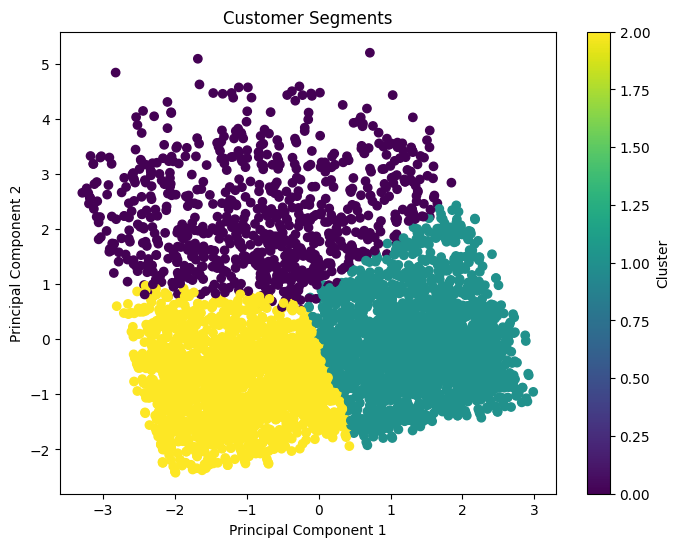

In [ ]:
# Final KMeans using optimal k
# Run KMeans 10 times choose best solution (n_init=10)
final_model = KMeans(   
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
df["Clusters"] = final_model.fit_predict(X_reduced)
# PCA Visualization (2D)
pca_vis = PCA(n_components=2)
pca_comp = pca_vis.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
plt.scatter(
    pca_comp[:,0],
    pca_comp[:,1],
    c=df['Clusters'],
    cmap='viridis'
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments")
plt.colorbar(label="Cluster")
plt.show()

In [16]:
# Cluster Profiling
print(df.groupby('Clusters')[
    ['Age','Experience','Income','Family','CCAvg']
].mean())

                Age  Experience      Income    Family     CCAvg
Clusters                                                       
0         43.427160   18.430864  147.375309  1.909877  4.909074
1         55.591582   30.296947   58.999075  2.369103  1.364554
2         35.171105    9.981262   60.128698  2.619822  1.362451


In [17]:
# Final Silhouette Score
silhouette = silhouette_score(X_reduced, df['Clusters'])
print("Silhouette Score:", silhouette)

Silhouette Score: 0.3430639905732926


In [18]:
# Save Model
with open('kmeans_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)